#Step 1: Install Libraries

In [1]:
%pip install -q -U transformers accelerate datasets sentencepiece scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 111.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 95.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [1]:
import os
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import files

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

from datasets import Dataset

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Libraries imported successfully!
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
import pandas as pd
import torch
import transformers
import datasets
import sklearn
import pyarrow

print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyArrow:", pyarrow.__version__)
print("GPU available:", torch.cuda.is_available())

Pandas: 3.0.6
PyTorch: 2.11.0+cu130
Transformers: 5.19.0
Datasets: 5.1.0
Scikit-learn: 1.9.1
PyArrow: 26.0.0
GPU available: True


In [3]:
%pip install --force-reinstall "pandas==2.2.3" "pyarrow==23.0.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.9/229.9 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 kB 20.9 MB/s eta 0:00:00
  Attempting uninstall: pytz
    Found existing installation: pytz 2025.2
    Uninstalling pytz-2025.2:
      Successfully uninstalled pytz-2025.2
  Attempting uninstall: tzdata
    Found existing installation: tzdata 2026.4
    Uninstalling tzdata-2026.4:
      Successfully uninstalled tzdata-2026.4
  Attempting uninstall: six
    Found existing installation: six 1.17.0
    Uninstalling six-1.17.0:
      Successfully uninstalled six-1

In [1]:
import pandas as pd
import pyarrow
import torch

print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)
print("GPU available:", torch.cuda.is_available())

Pandas: 2.2.3
PyArrow: 23.0.1
GPU available: True


#STEP 1 — Verify your environment

In [2]:
import pandas as pd
import torch
import transformers
import datasets
import sklearn
import pyarrow

print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyArrow:", pyarrow.__version__)
print("GPU available:", torch.cuda.is_available())

assert pd.__version__ == "2.2.3", (
    "Pandas version is incorrect. "
    "Install pandas==2.2.3 and restart the runtime."
)

assert torch.cuda.is_available(), (
    "GPU is not enabled. Enable a GPU in Colab settings."
)

Pandas: 2.2.3
PyTorch: 2.11.0+cu130
Transformers: 5.19.0
Datasets: 5.1.0
Scikit-learn: 1.9.1
PyArrow: 23.0.1
GPU available: True


#STEP 2 — Upload your CSV files

In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving TeClass_development_data.csv to TeClass_development_data (1).csv
Saving TeClass_testing_data.csv to TeClass_testing_data (1).csv
Saving TeClass_training_data.csv to TeClass_training_data (1).csv
Uploaded files:
TeClass_development_data (1).csv
TeClass_testing_data (1).csv
TeClass_training_data (1).csv


#STEP 3 — Load the datasets

In [4]:
import pandas as pd

train_df = pd.read_csv("TeClass_training_data.csv")
dev_df = pd.read_csv("TeClass_development_data.csv")
test_df = pd.read_csv("TeClass_testing_data.csv")

print("Training shape:", train_df.shape)
print("Development shape:", dev_df.shape)
print("Testing shape:", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
print("\nOriginal label counts:")
print(train_df["label"].value_counts())

Training shape: (18324, 5)
Development shape: (3927, 5)
Testing shape: (3927, 5)

Columns: ['id', 'url', 'article', 'headline', 'label']

Original label counts:
label
MREL    7105
HREL    5962
LREL    5257
Name: count, dtype: int64


#STEP 4 — Merge the labels

In [5]:
label_mapping = {
    "HREL": "RELEVANT",
    "MREL": "RELEVANT",
    "LREL": "LESS_RELEVANT"
}

numeric_mapping = {
    "LESS_RELEVANT": 0,
    "RELEVANT": 1
}

def prepare_labels(df):
    df = df.copy()

    df["label"] = (
        df["label"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    df["merged_label"] = df["label"].map(label_mapping)

    if df["merged_label"].isna().any():
        unknown = df.loc[
            df["merged_label"].isna(), "label"
        ].unique()

        raise ValueError(f"Unknown labels: {unknown}")

    df["labels"] = df["merged_label"].map(numeric_mapping).astype("int64")

    return df

train_df = prepare_labels(train_df)
dev_df = prepare_labels(dev_df)
test_df = prepare_labels(test_df)

print("Training labels:")
print(train_df["merged_label"].value_counts())

print("\nDevelopment labels:")
print(dev_df["merged_label"].value_counts())

print("\nTest labels:")
print(test_df["merged_label"].value_counts())

Training labels:
merged_label
RELEVANT         13067
LESS_RELEVANT     5257
Name: count, dtype: int64

Development labels:
merged_label
RELEVANT         2800
LESS_RELEVANT    1127
Name: count, dtype: int64

Test labels:
merged_label
RELEVANT         2801
LESS_RELEVANT    1126
Name: count, dtype: int64


#STEP 5 — Prepare the headline and article text

In [6]:
def prepare_text(df):
    df = df.copy()

    df["headline"] = df["headline"].fillna("").astype(str)
    df["article"] = df["article"].fillna("").astype(str)

    df["text"] = (
        "Headline: " + df["headline"]
        + " Article: " + df["article"]
    )

    df = df[df["text"].str.strip().ne("")].copy()

    return df.reset_index(drop=True)

train_df = prepare_text(train_df)
dev_df = prepare_text(dev_df)
test_df = prepare_text(test_df)

print("Training examples:", len(train_df))
print("Development examples:", len(dev_df))
print("Test examples:", len(test_df))

print("\nSample:")
print(train_df["text"].iloc[0][:300])

Training examples: 18324
Development examples: 3927
Test examples: 3927

Sample:
Headline: వ్యక్తి ప్రాణాలు తీసిన “రాజు గారి గది” సినిమా Article: హైదరాబాద్ : “రాజు గారి గది” సినిమా చూస్తూ ఓ ప్రేక్షకుడు చనిపోయాడు . తెలుగు హారర్ సినిమా రాజు గారి గది టివి యాంకర్ ఓంకార్ డైరక్షన్లో తెరకెక్కింది . నగరంలోని బహదూర్పూరాలోని మెట్రో థియేటర్లో ప్రదర్శితమవుతున్న ఈ సినిమాకు వెళ్లిన అమర్నాథ్ (


#STEP 6 — Load a fresh mDeBERTa model

In [7]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "microsoft/mdeberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "LESS_RELEVANT",
        1: "RELEVANT"
    },
    label2id={
        "LESS_RELEVANT": 0,
        "RELEVANT": 1
    },
    torch_dtype=torch.float32
)

print("Fresh model loaded successfully!")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias     

Fresh model loaded successfully!


#STEP 7 — Verify model parameters

In [8]:
bad_parameters = []

for name, param in model.named_parameters():
    if not torch.isfinite(param).all():
        bad_parameters.append(name)

print("Invalid parameter tensors:", len(bad_parameters))
print("First invalid parameters:", bad_parameters[:10])

assert len(bad_parameters) == 0, (
    "The model contains NaN or infinite parameters. "
    "Do not train."
)

print("All model parameters are finite!")

Invalid parameter tensors: 0
First invalid parameters: []
All model parameters are finite!


#STEP 8 — Create Hugging Face datasets

In [9]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[["text", "labels"]].reset_index(drop=True)
)

dev_dataset = Dataset.from_pandas(
    dev_df[["text", "labels"]].reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df[["text", "labels"]].reset_index(drop=True)
)

print("Datasets created successfully!")
print(train_dataset[0])

Datasets created successfully!
{'text': 'Headline: వ్యక్తి ప్రాణాలు తీసిన “రాజు గారి గది” సినిమా Article: హైదరాబాద్ : “రాజు గారి గది” సినిమా చూస్తూ ఓ ప్రేక్షకుడు చనిపోయాడు . తెలుగు హారర్ సినిమా రాజు గారి గది టివి యాంకర్ ఓంకార్ డైరక్షన్లో తెరకెక్కింది . నగరంలోని బహదూర్పూరాలోని మెట్రో థియేటర్లో ప్రదర్శితమవుతున్న ఈ సినిమాకు వెళ్లిన అమర్నాథ్ ( 55 ) అక్కడికక్కడే చనిపోయాడు . సమాచారం తెలుసుకున్న పోలీసులు సంఘటనా స్థలానికి చేరుకొని మృత దేహాన్ని స్వాధీనం చేసుకొని పోస్టుమార్టం నిమిత్తం ఆస్పత్రికి తరలించారు . గుండె సంబంధించిన వ్యాధి గ్రస్తులు సినిమా వెళ్లేటప్పుడు తగు జాగ్రత్తలు తీసుకొవాలని పలువురు అభిప్రాయపడుతున్నారు .', 'labels': 1}


#STEP 9 — Tokenize the datasets

In [10]:
MAX_LENGTH = 256

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

dev_dataset = dev_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("Tokenization completed!")
print(train_dataset[0].keys())

Map:   0%|          | 0/18324 [00:00<?, ? examples/s]

Map:   0%|          | 0/3927 [00:00<?, ? examples/s]

Map:   0%|          | 0/3927 [00:00<?, ? examples/s]

Tokenization completed!
dict_keys(['labels', 'input_ids', 'token_type_ids', 'attention_mask'])


#STEP 10 — Create the data collator

In [11]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Data collator created!")

Data collator created!


#STEP 11 — Test the model before training

In [12]:
device = torch.device("cuda")

model.to(device)
model.eval()

batch = data_collator([
    train_dataset[i] for i in range(2)
])

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

with torch.no_grad():
    outputs = model(**batch)

print("Logits:")
print(outputs.logits)

print("\nLoss:")
print(outputs.loss)

print("\nLogits finite:",
      torch.isfinite(outputs.logits).all().item())

print("Loss finite:",
      torch.isfinite(outputs.loss).item())

assert torch.isfinite(outputs.logits).all(), (
    "Invalid logits detected. Do not train."
)

assert torch.isfinite(outputs.loss), (
    "Invalid loss detected. Do not train."
)

print("\nForward pass successful!")

Logits:
tensor([[-0.2547, -0.0721],
        [-0.2529, -0.0719]], device='cuda:0')

Loss:
tensor(0.6064, device='cuda:0')

Logits finite: True
Loss finite: True

Forward pass successful!


#STEP 12 — Define evaluation metrics

In [13]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    _, _, f1_weighted, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted
    }

print("Metrics configured!")

Metrics configured!


#STEP 13 — Configure training

In [14]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./TeClass_Merged_Results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=5e-6,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,

    num_train_epochs=3,
    weight_decay=0.01,
    max_grad_norm=1.0,

    fp16=False,
    bf16=False,

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    save_total_limit=2,
    logging_steps=100,
    report_to="none",
    seed=42
)

print("Training arguments configured!")

Training arguments configured!


#STEP 14 — Initialize the Trainer

In [15]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")

Trainer initialized successfully!


#STEP 15 — Train the model

In [16]:
training_results = trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,1.153536,0.636492,0.796537,0.755920,0.722659,0.735200,0.789494
2,1.304757,0.884759,0.797046,0.762064,0.710822,0.727488,0.786143
3,1.221223,0.944290,0.792717,0.753700,0.709377,0.724416,0.782865


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

#STEP 16 — Check the training history

In [17]:
for record in trainer.state.log_history:
    if "loss" in record or "eval_loss" in record:
        print(record)

{'loss': 1.2137250518798828, 'grad_norm': 28.597291946411133, 'learning_rate': 4.963981663392273e-06, 'epoch': 0.021829294913774284, 'step': 100}
{'loss': 1.1673809814453124, 'grad_norm': 22.255756378173828, 'learning_rate': 4.9275995052026495e-06, 'epoch': 0.04365858982754857, 'step': 200}
{'loss': 1.1225694274902345, 'grad_norm': 10.662809371948242, 'learning_rate': 4.891217347013025e-06, 'epoch': 0.06548788474132286, 'step': 300}
{'loss': 1.2226964569091796, 'grad_norm': 23.83038330078125, 'learning_rate': 4.854835188823401e-06, 'epoch': 0.08731717965509714, 'step': 400}
{'loss': 1.0398233795166016, 'grad_norm': 62.854530334472656, 'learning_rate': 4.818453030633777e-06, 'epoch': 0.10914647456887143, 'step': 500}
{'loss': 1.0561551666259765, 'grad_norm': 63.599822998046875, 'learning_rate': 4.782070872444154e-06, 'epoch': 0.13097576948264572, 'step': 600}
{'loss': 0.9838753509521484, 'grad_norm': 20.0207576751709, 'learning_rate': 4.74568871425453e-06, 'epoch': 0.15280506439642, 'st

#STEP 17 — Test evaluation

In [18]:
test_results = trainer.predict(test_dataset)

true_labels = test_results.label_ids
predictions = np.argmax(
    test_results.predictions,
    axis=1
)

print("Test metrics:")

for key, value in test_results.metrics.items():
    print(f"{key}: {value:.4f}")

print("\nActual label counts:")
print(np.unique(true_labels, return_counts=True))

print("\nPredicted label counts:")
print(np.unique(predictions, return_counts=True))

Test metrics:
test_loss: 0.6004
test_accuracy: 0.8098
test_precision_macro: 0.7760
test_recall_macro: 0.7352
test_f1_macro: 0.7502
test_f1_weighted: 0.8022
test_runtime: 104.4801
test_samples_per_second: 37.5860
test_steps_per_second: 18.7980

Actual label counts:
(array([0, 1]), array([1126, 2801]))

Predicted label counts:
(array([0, 1]), array([ 883, 3044]))


#STEP 18 — Classification report

In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_labels,
        predictions,
        labels=[0, 1],
        target_names=[
            "LESS_RELEVANT",
            "RELEVANT"
        ],
        digits=4,
        zero_division=0
    )
)

               precision    recall  f1-score   support

LESS_RELEVANT     0.7146    0.5604    0.6282      1126
     RELEVANT     0.8374    0.9100    0.8722      2801

     accuracy                         0.8098      3927
    macro avg     0.7760    0.7352    0.7502      3927
 weighted avg     0.8022    0.8098    0.8022      3927



#STEP 19 — Confusion matrix

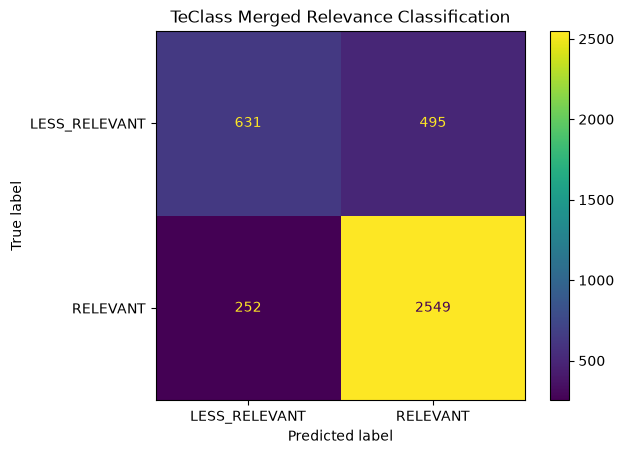

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    true_labels,
    predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "LESS_RELEVANT",
        "RELEVANT"
    ]
)

display.plot(values_format="d")
plt.title("TeClass Merged Relevance Classification")
plt.show()

#STEP 20 — Save the model

In [23]:
MODEL_OUTPUT_DIR = "./TeClass_Merged_Classes_Model"

trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


#STEP 21 — Save evaluation metrics

In [25]:
import json

evaluation_results = {
    "experiment": "TeClass Merged Relevance Classification",
    "model": MODEL_NAME,
    "task": "Binary classification",
    "label_mapping": {
        "HREL": "RELEVANT",
        "MREL": "RELEVANT",
        "LREL": "LESS_RELEVANT"
    },
    "max_sequence_length": MAX_LENGTH,
    "test_metrics": {
        key: float(value)
        for key, value in test_results.metrics.items()
    }
}

with open("TeClass_evaluation_results.json", "w") as f:
    json.dump(evaluation_results, f, indent=4)

print(json.dumps(evaluation_results, indent=4))

{
    "experiment": "TeClass Merged Relevance Classification",
    "model": "microsoft/mdeberta-v3-base",
    "task": "Binary classification",
    "label_mapping": {
        "HREL": "RELEVANT",
        "MREL": "RELEVANT",
        "LREL": "LESS_RELEVANT"
    },
    "max_sequence_length": 256,
    "test_metrics": {
        "test_loss": 0.6004188060760498,
        "test_accuracy": 0.8097784568372803,
        "test_precision_macro": 0.7759971531170615,
        "test_recall_macro": 0.7352114475735956,
        "test_f1_macro": 0.7501858403650639,
        "test_f1_weighted": 0.8022284016742206,
        "test_runtime": 104.4801,
        "test_samples_per_second": 37.586,
        "test_steps_per_second": 18.798
    }
}


#STEP 22 — Download the trained model

In [26]:
import shutil
from google.colab import files

shutil.make_archive(
    "TeClass_Merged_Classes_Model",
    "zip",
    root_dir=".",
    base_dir="TeClass_Merged_Classes_Model"
)

files.download("TeClass_Merged_Classes_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#STEP 23 — Download the evaluation results

In [27]:
files.download("TeClass_evaluation_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>